In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [4]:


df = pd.read_csv("AirQualityUCI.csv", encoding='latin1', sep = ";", decimal = ',', na_values=["NA", "NaN", "", "-200", "?", ""] )


df.head()


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [5]:
df = df.drop(["Time", "Date", "Unnamed: 15", "Unnamed: 16"], axis = 1)

df.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [6]:
print(df.columns)

Index(['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)',
       'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
       'T', 'RH', 'AH'],
      dtype='str')


In [7]:
cols = df.columns

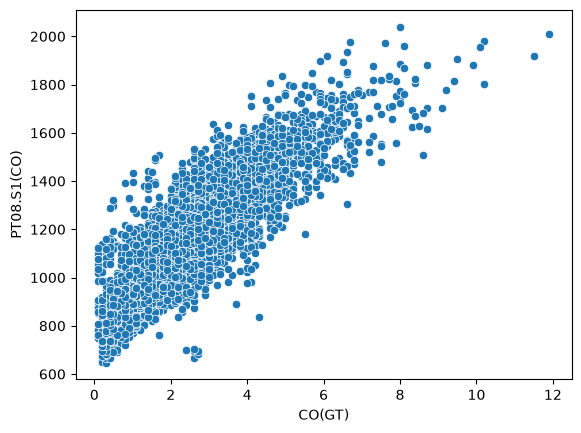

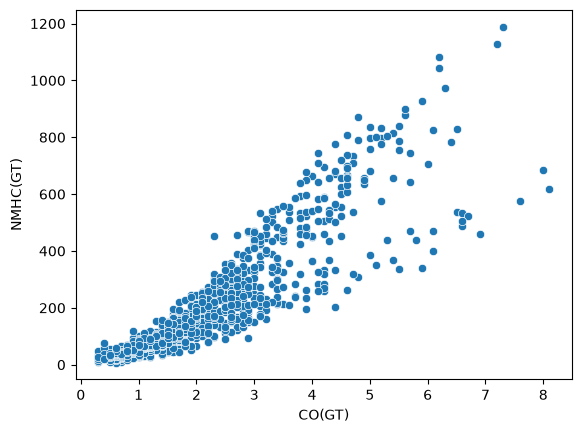

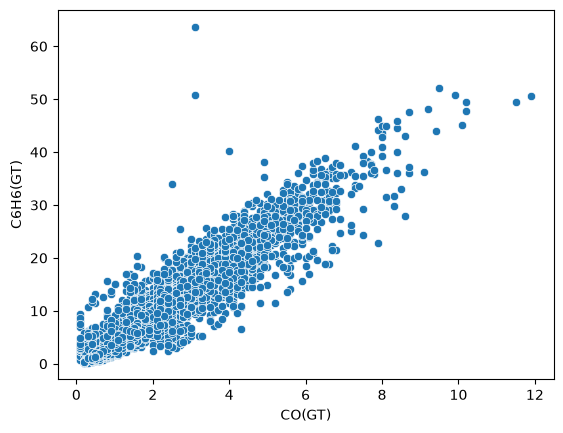

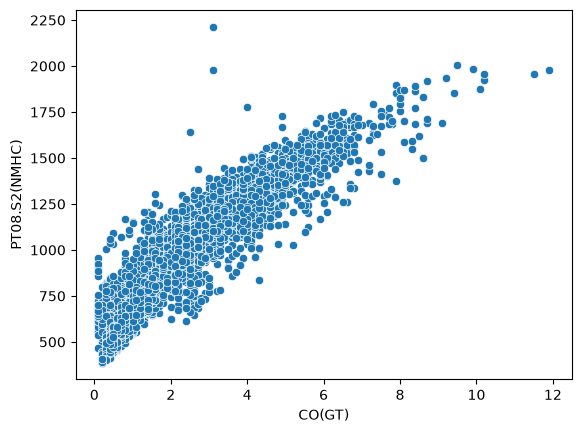

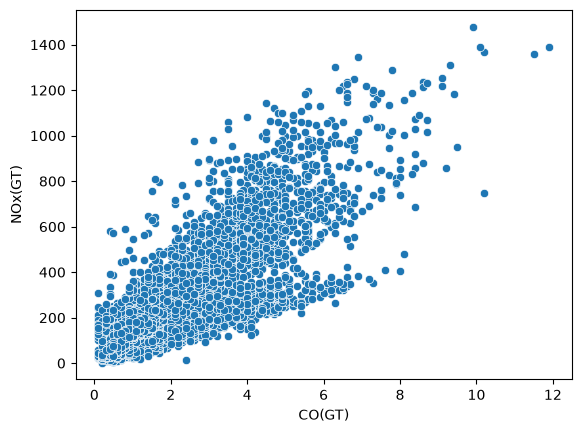

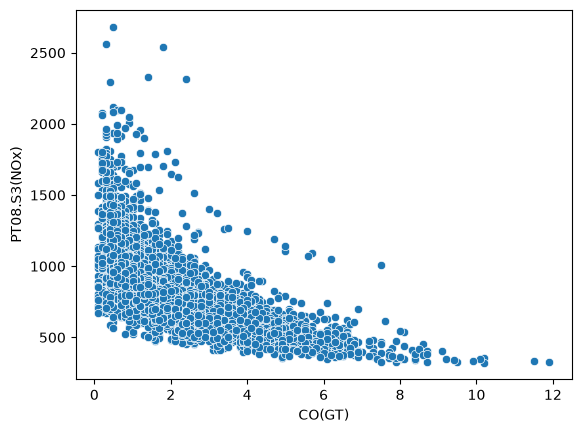

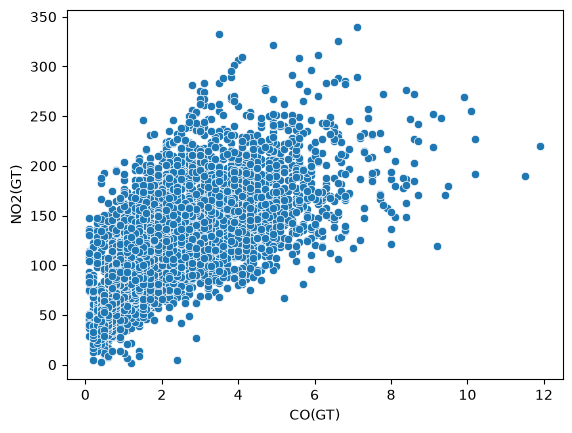

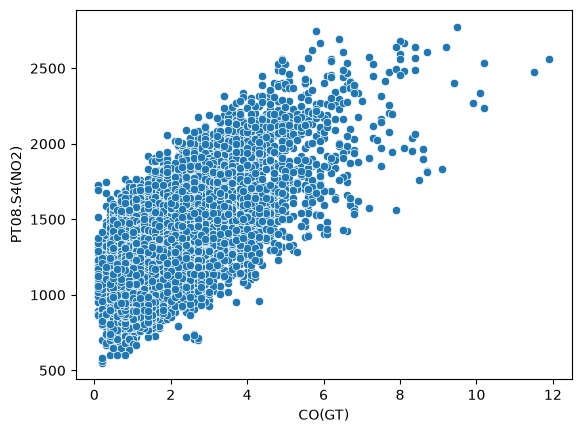

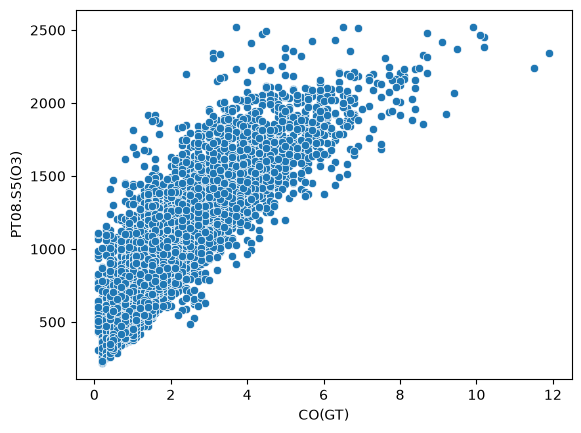

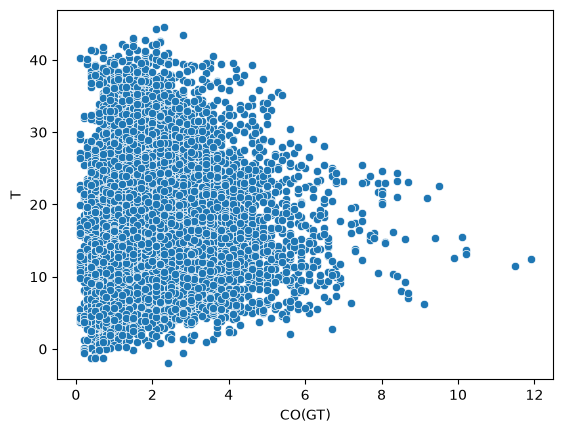

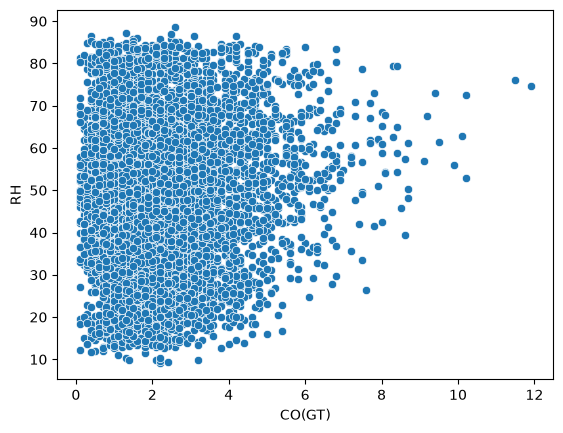

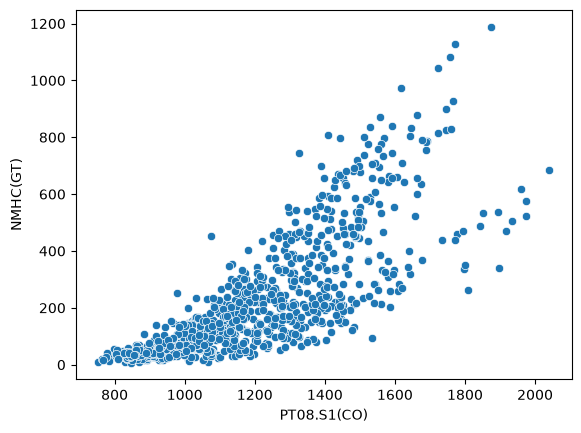

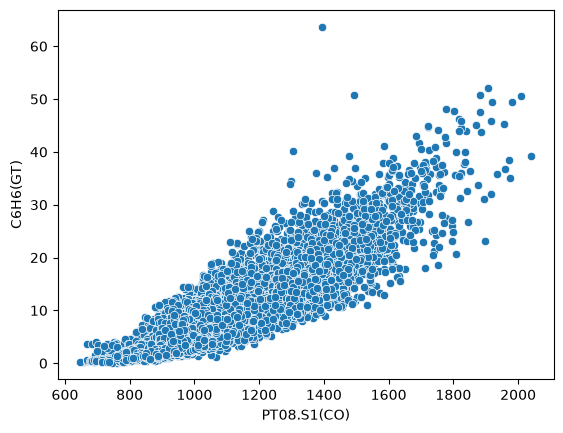

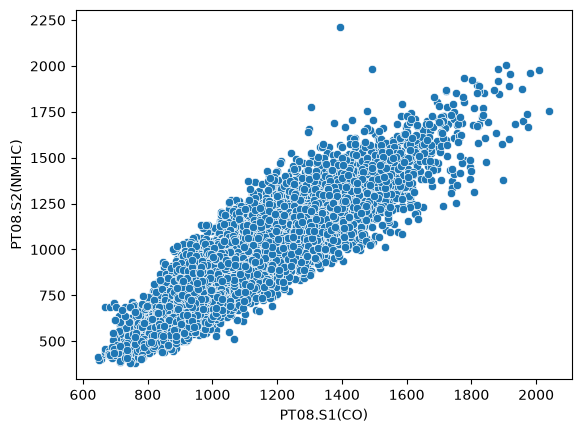

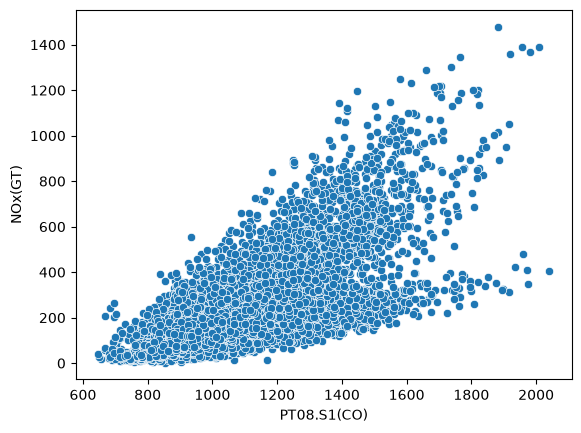

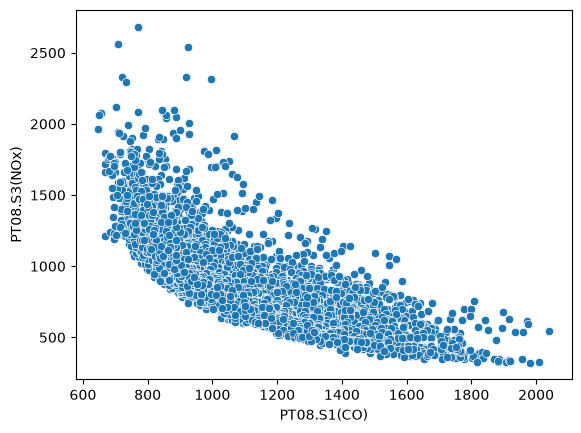

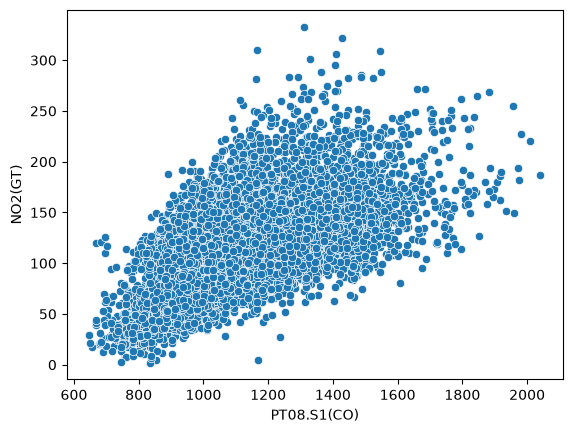

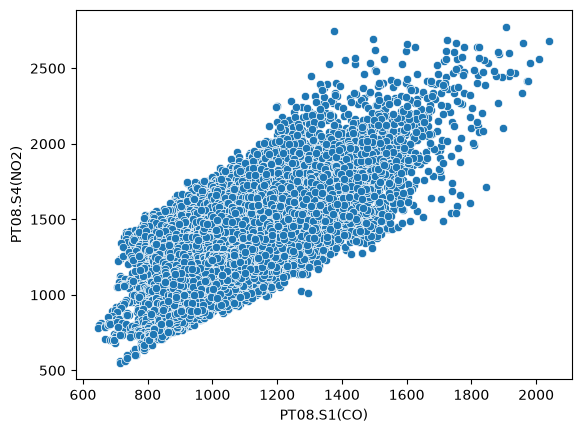

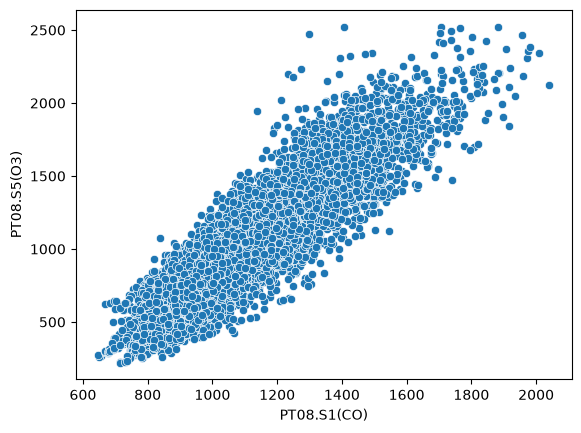

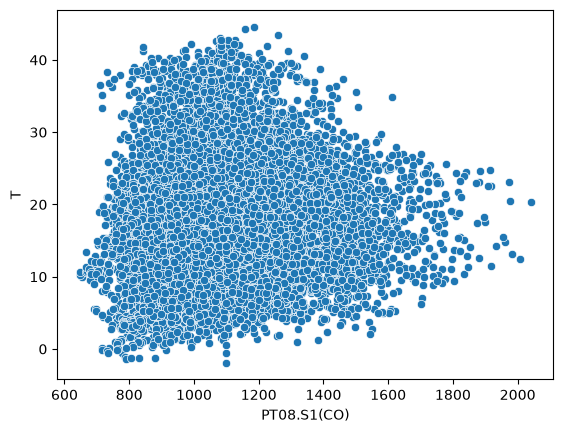

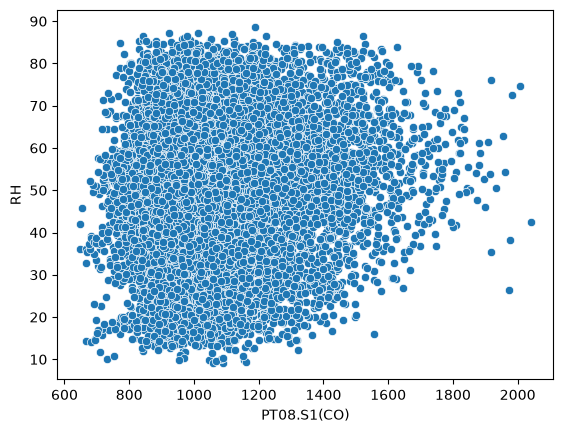

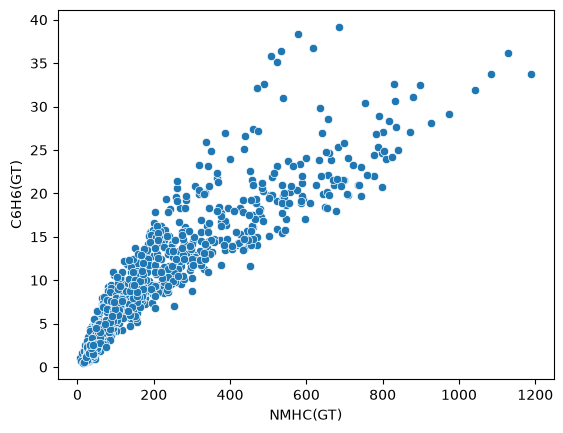

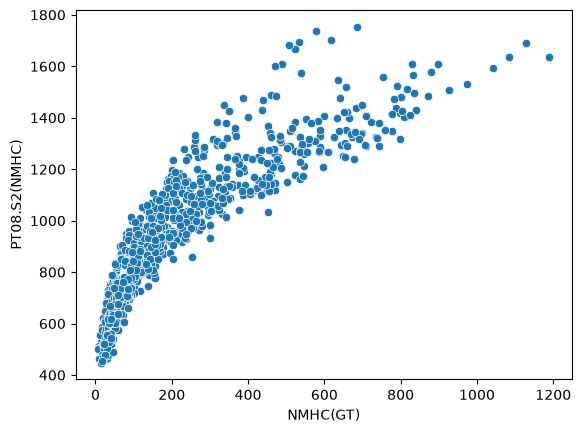

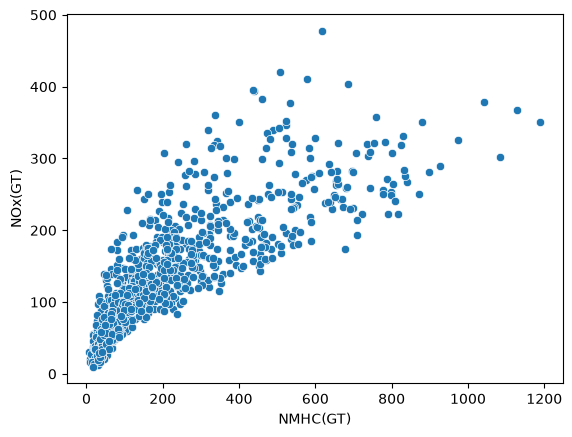

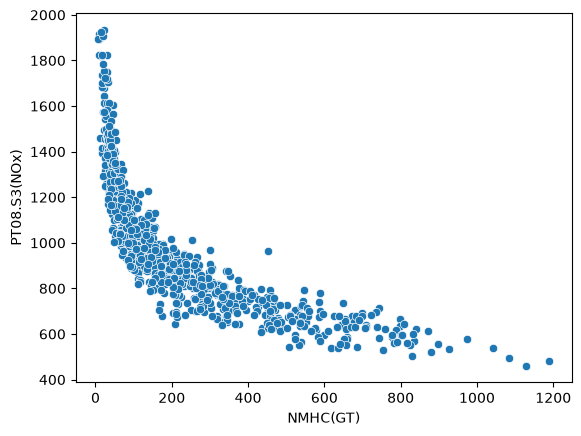

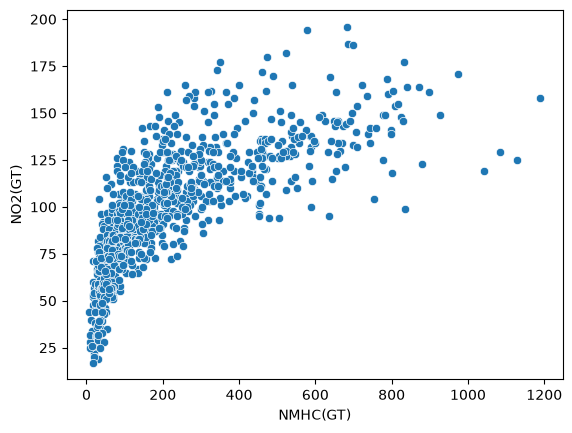

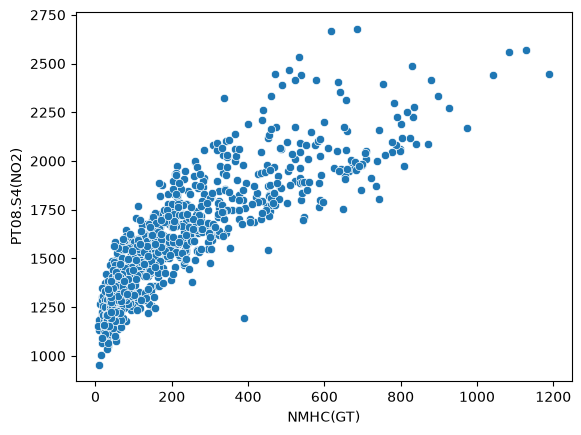

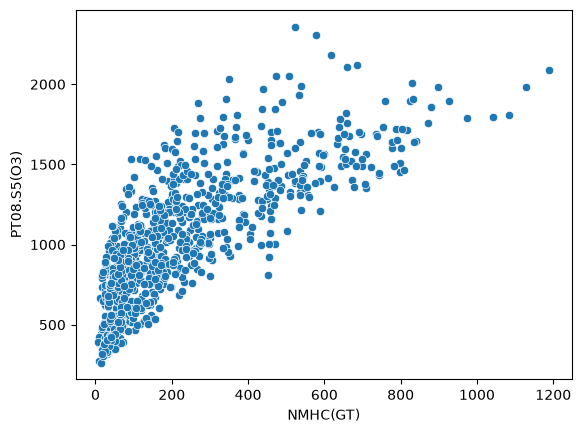

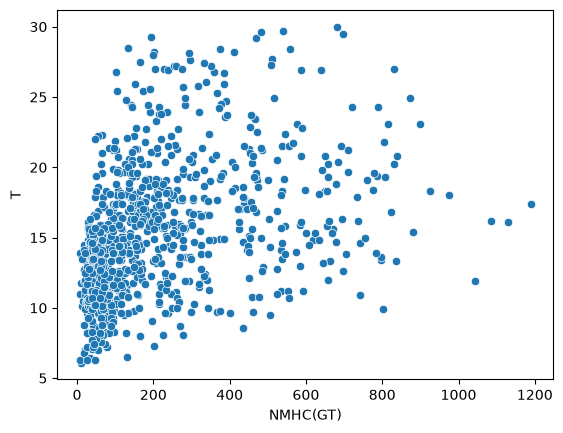

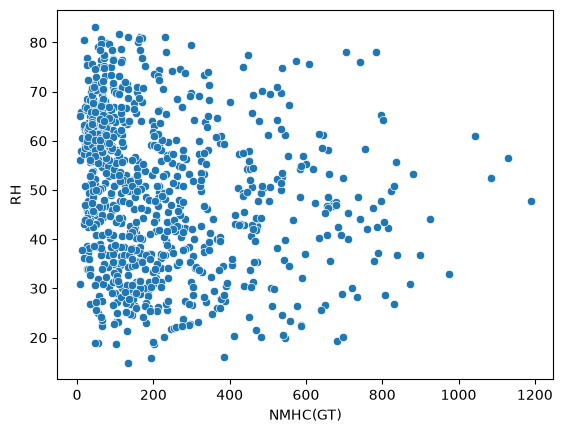

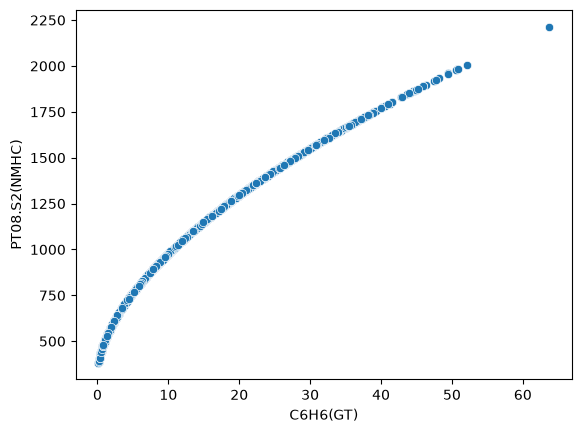

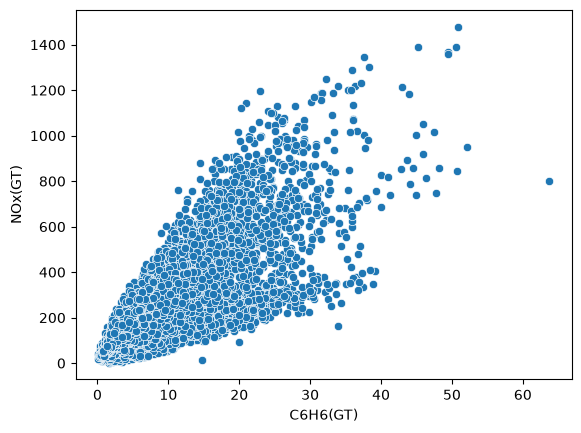

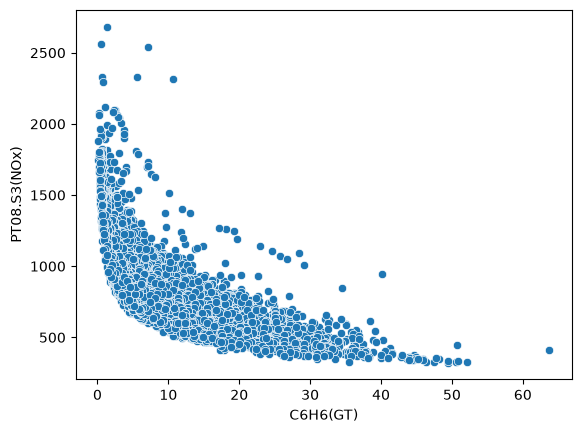

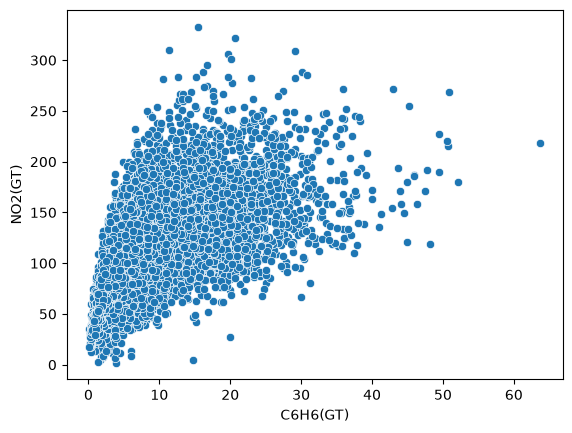

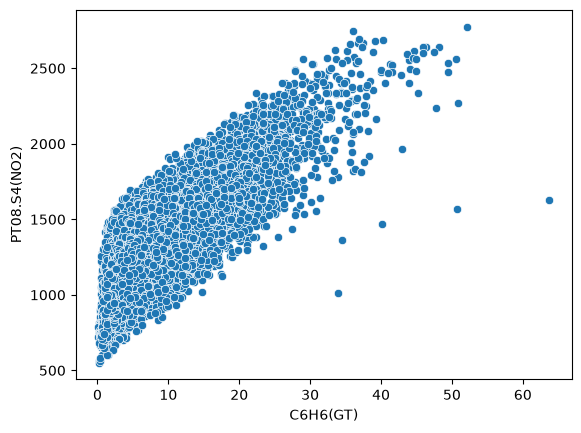

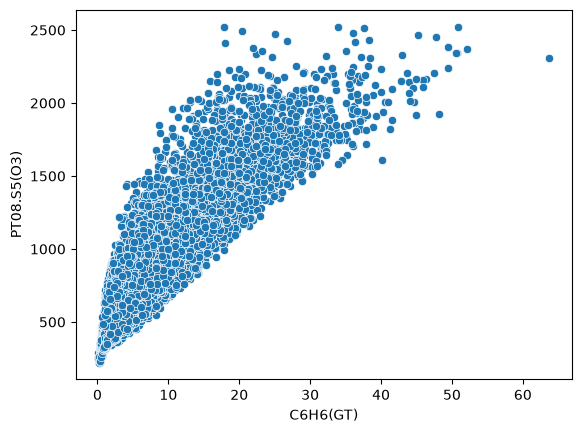

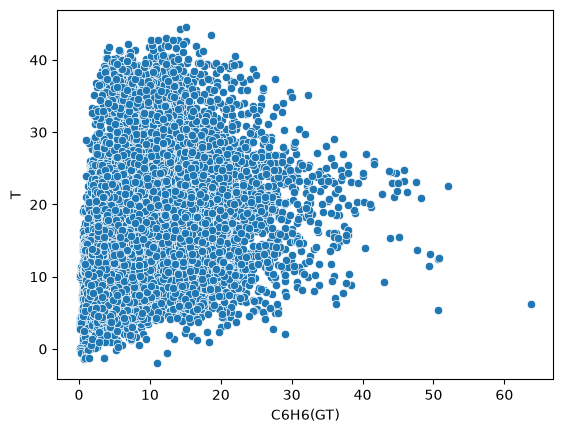

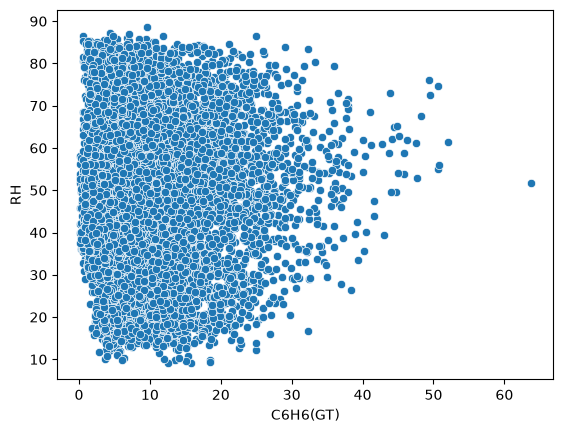

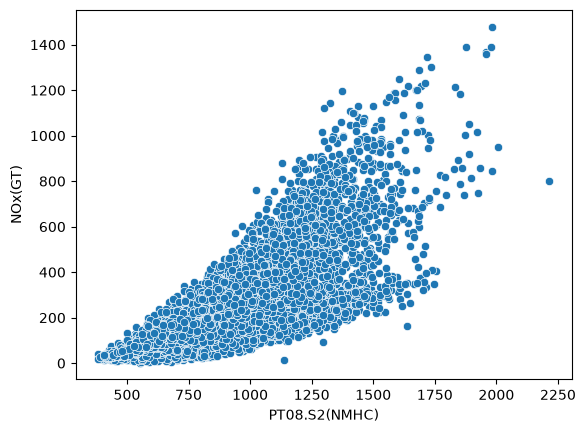

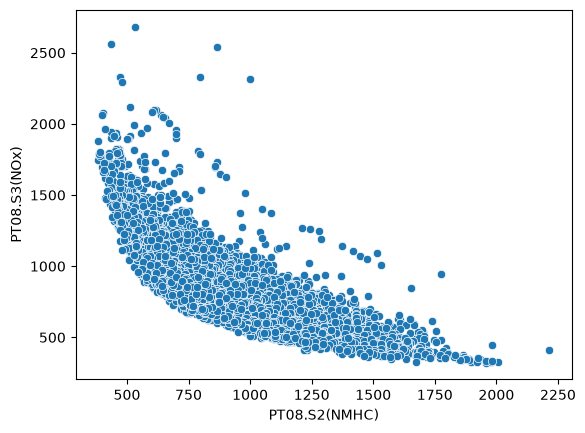

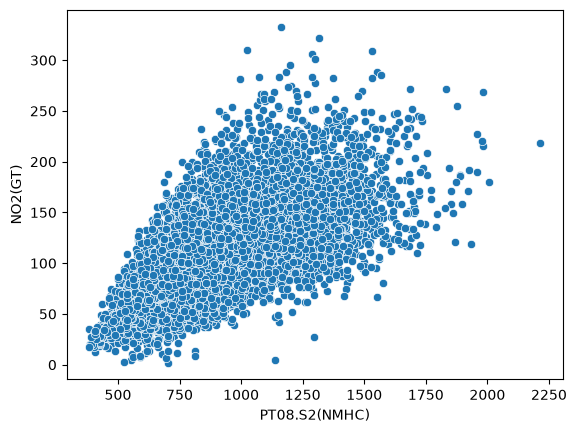

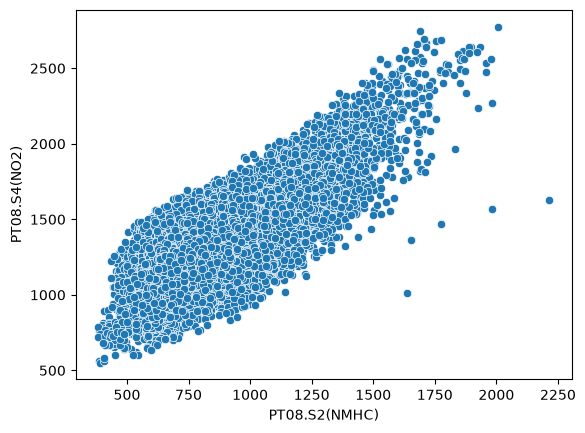

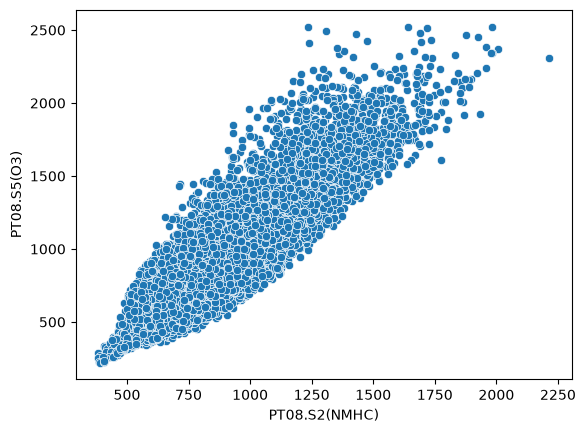

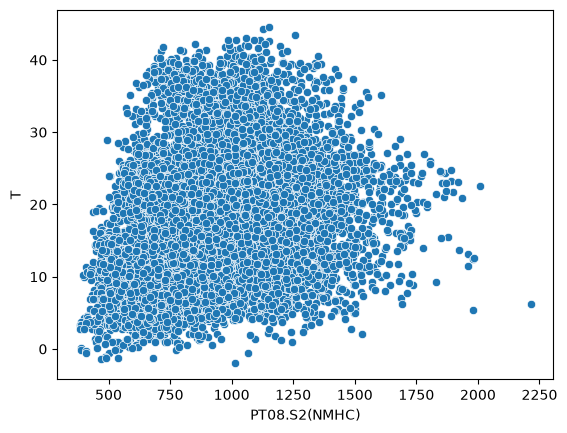

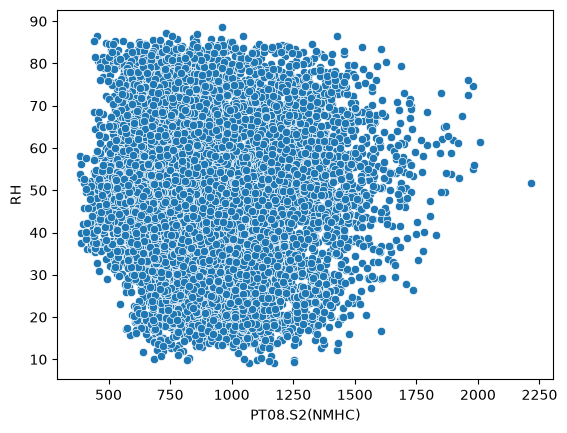

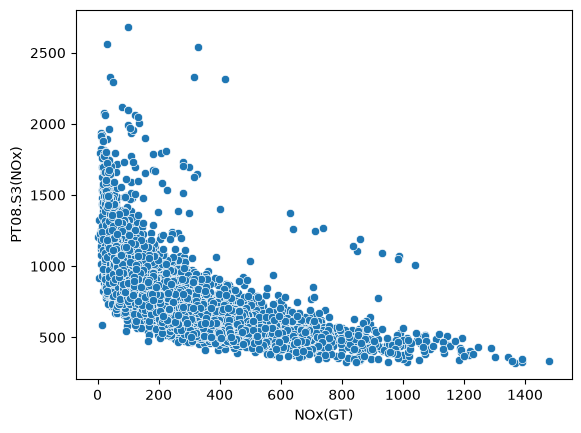

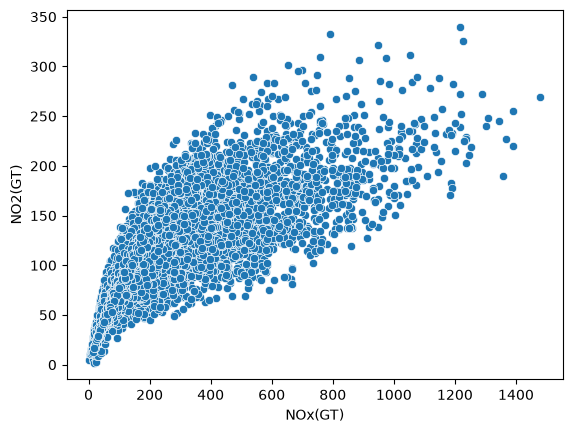

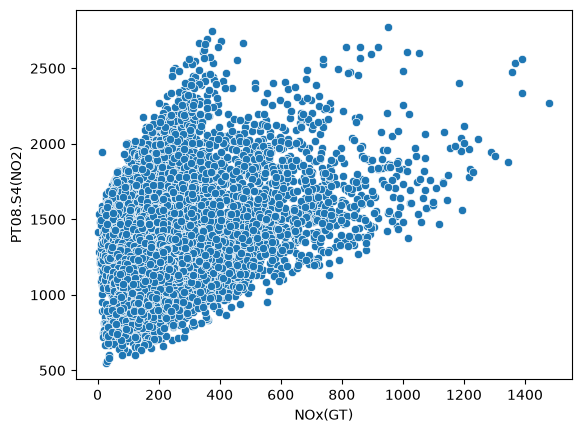

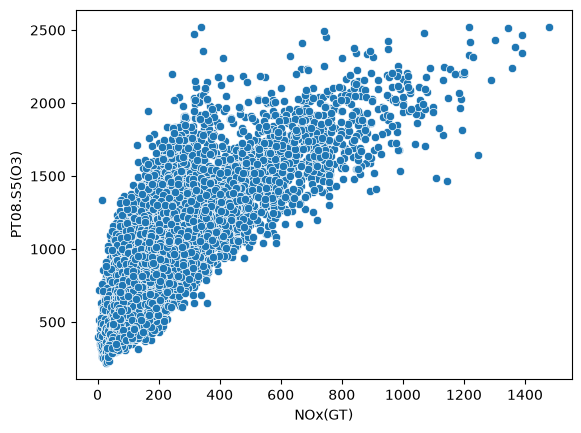

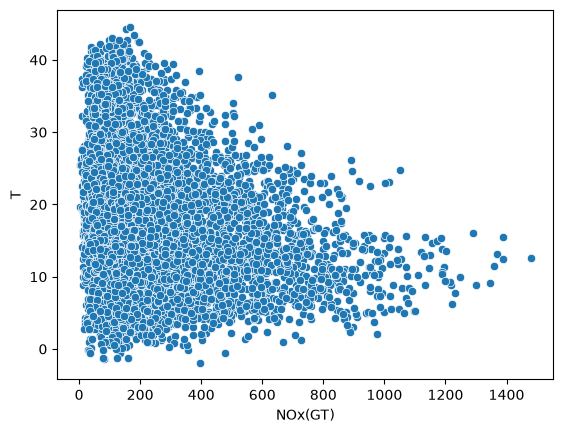

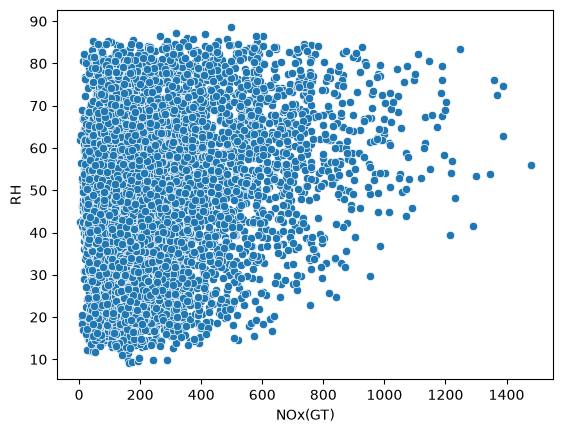

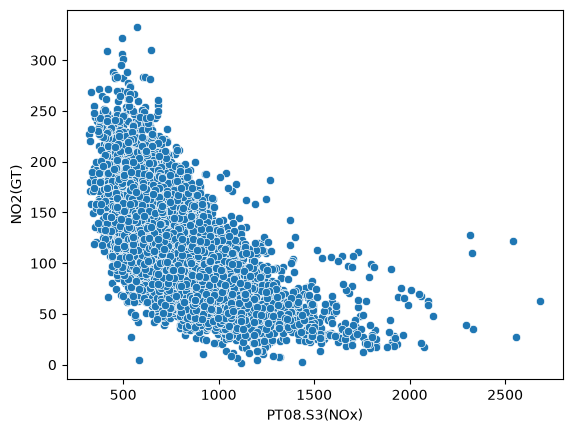

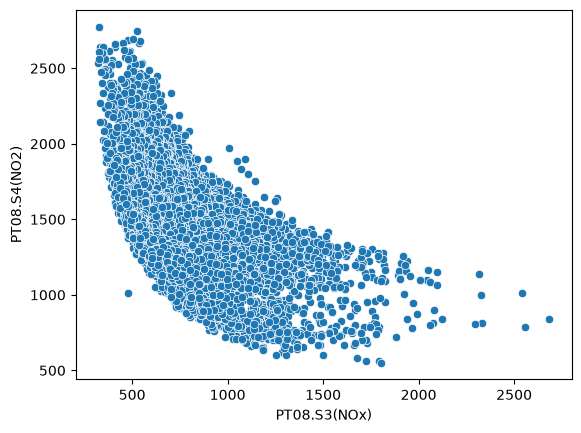

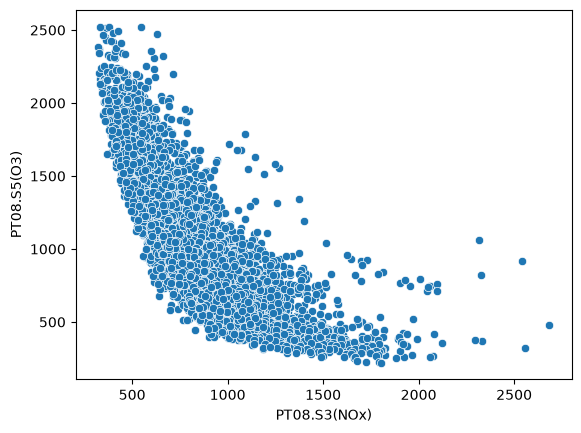

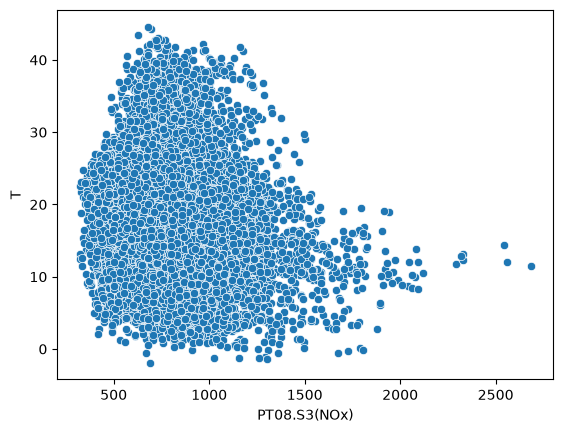

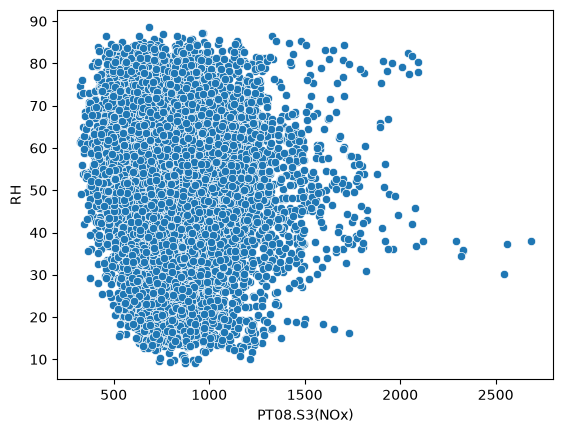

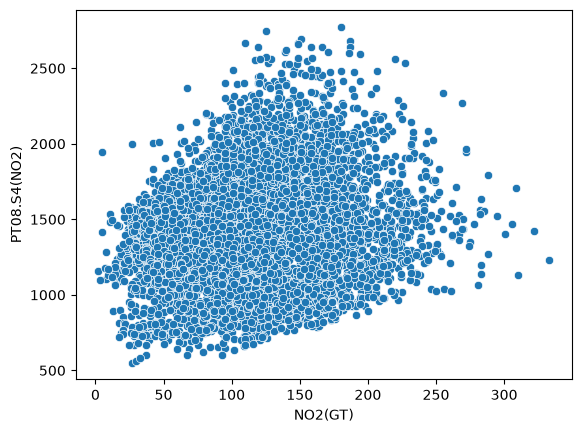

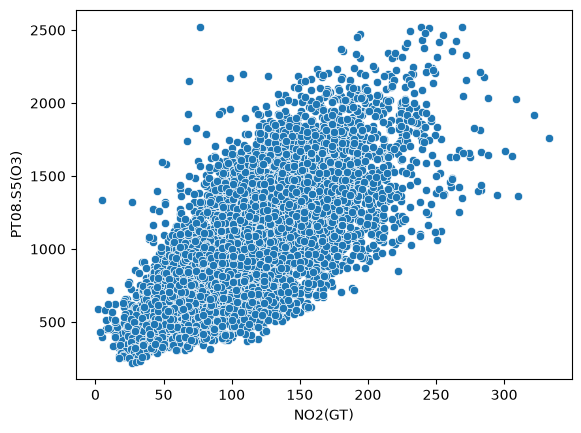

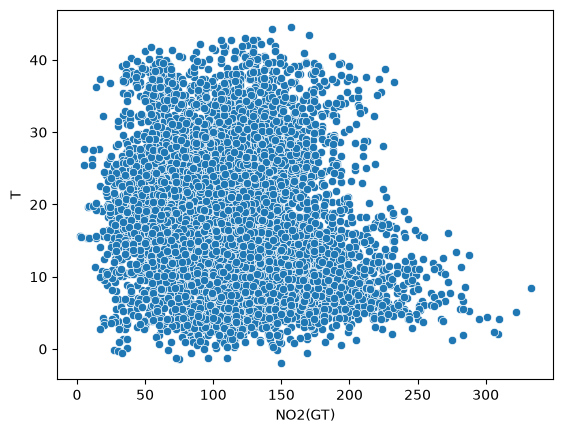

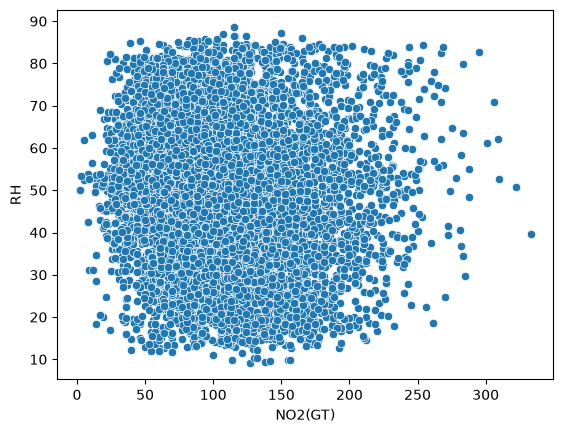

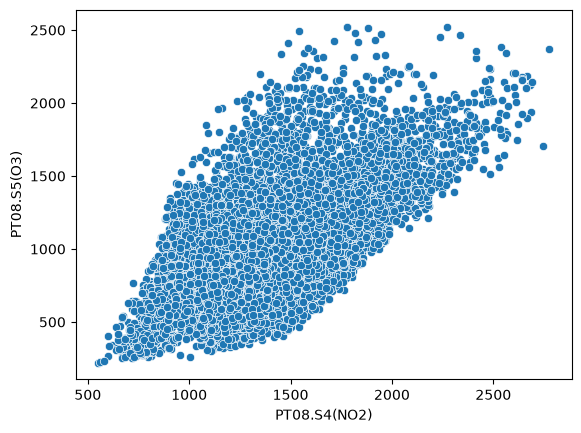

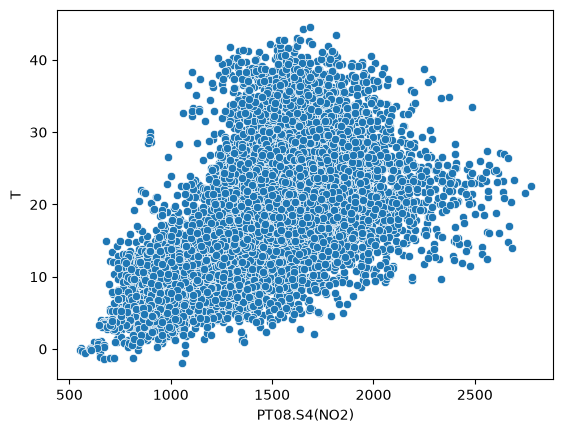

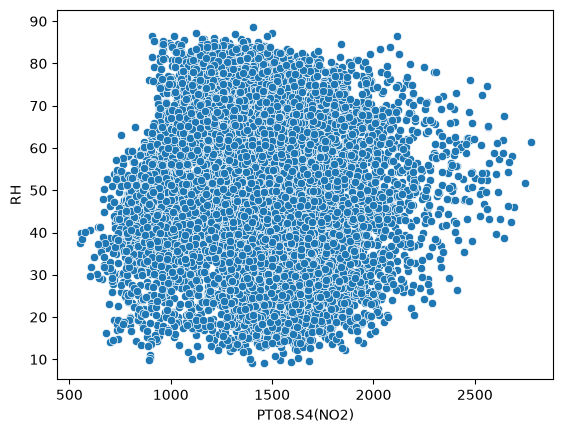

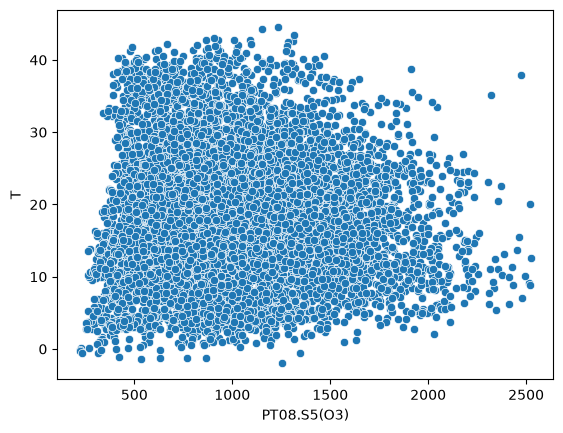

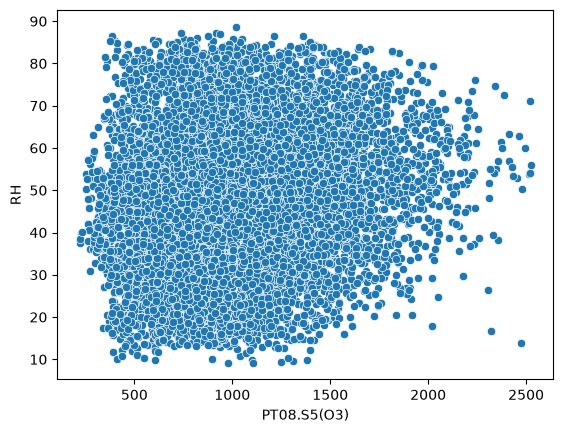

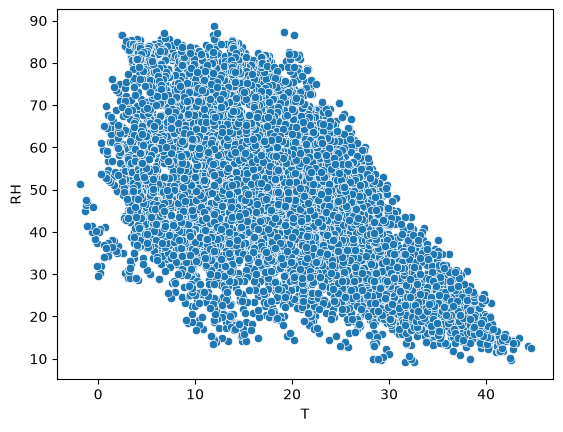

In [8]:
for i in range(len(cols)-1):
  for j in range(i+1, len(cols)-1):
    x_label = cols[i]
    y_label = cols[j]
    sns.scatterplot(x=x_label, y = y_label, data = df)
    plt.show()
    #hue will separate the three different classes into 3 different hues?/colours
    #we are basically comparing every parameter with each other

In [9]:
############

In [10]:
from sklearn.cluster import KMeans

In [11]:
len(X)

NameError: name 'X' is not defined

Above, because we've used such a harsh code of removing an entire row when an NA value is found, we are left with **NO rows** whatsoever- therefore we will go through **Imputation** instead

In [ ]:
#####################

Your dataset has missing or invalid values (-200 in this air quality dataset).

If you simply call dropna(), you remove any row with at least one missing value. Since **almost every row** has **at least one -200**, you lose all rows → shape = (0, 15).

So instead of throwing away rows, we should **fill in (impute) the missing values with reasonable estimates.**

In [ ]:
###############

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline

# 1) Replace sentinel and select numeric
df2 = df.replace(-200, np.nan)
X = df2.select_dtypes(include="number")
X = df2[cols]                       # <- keep only the intended features
feature_names = X.columns.tolist()


# 2) Build preprocessing pipeline ONLY
preproc = make_pipeline(
    SimpleImputer(strategy="median"),   # 1. Fill missing values with median
    StandardScaler(),                   # 2. Normalize data (important for KMeans)
)



#########################
# 3) Fit *and apply* the preprocessing to get a clean matrix
X_proc = preproc.fit_transform(X)   # <-- this is the key step you missed



What happened inside?

**SimpleImputer**: Each column’s NaN is **replaced** by its **median** (calculated from non-missing values).

**StandardScaler**: Scales features to mean 0, std 1 → **prevents large-scale features** (like PT08.S1(CO) ~ 1000s) **from dominating small ones** (like `C6H6(GT) ~ single digits).

KMeans: Now runs on a **“complete”, normalized dataset.**

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42).fit(X_proc)

In [ ]:
clusters = kmeans.labels_

In [ ]:
clusters

array([0, 0, 0, ..., 0, 0, 0], dtype=int32)

In [ ]:
np.shape(df.columns)

(13,)

In [ ]:
np.shape(X)

(9471, 13)

In [ ]:
len(X.columns)

13

In [ ]:
len(df.columns)

13

In [ ]:
cluster_df = X.copy()
cluster_df["class"] = kmeans.labels_
#here we added the kmeans labels as the extra column of "class"-
#idk if this was a good idea just yet

In [ ]:
cluster_df = pd.DataFrame(np.hstack((X, kmeans.labels_.reshape(-1,1))), columns = cluster_df.columns)

In [ ]:
#################################

In [ ]:
#Now we will PCA project this dataframe to
#make it into a 2D human-friendly plot to observe

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(X_proc)  # same data you clustered on
cluster_df["PC1"] = pcs[:, 0]
cluster_df["PC2"] = pcs[:, 1]

In [ ]:
labels = kmeans.fit_predict(X_proc)
cluster_df["class"] = labels

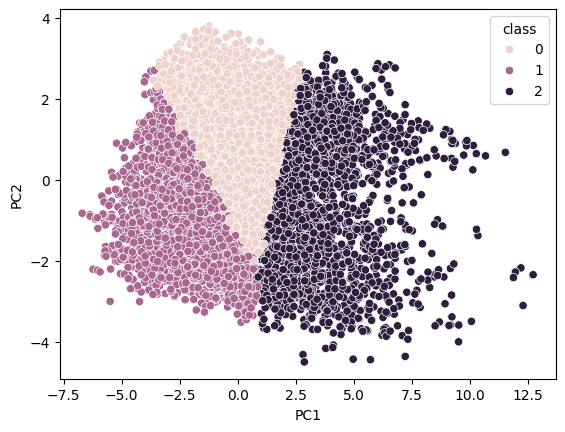

In [ ]:
sns.scatterplot(x="PC1", y="PC2", hue="class", data=cluster_df)
plt.show()

---
This above code has combined the data into **two principal components** in order for it to ***be observed clearly in a 2D array***.

----
To find out what each of these components represent, we need the **PCA loadings**.

The PCA loadings will show the ***contribution score of each original feature to each of the two PCs***.

---

In [ ]:
import pandas as pd

names = X.columns.tolist()

loadings = pd.DataFrame(
    pca.components_.T,     # transpose so rows = features
    columns=["PC1", "PC2"],
    index= names
)
print("PCA loadings")
print(loadings.round(3))

PCA loadings
                 PC1    PC2
CO(GT)         0.339 -0.103
PT08.S1(CO)    0.361 -0.014
NMHC(GT)       0.118  0.041
C6H6(GT)       0.367  0.066
PT08.S2(NMHC)  0.372  0.083
NOx(GT)        0.284 -0.308
PT08.S3(NOx)  -0.324 -0.019
NO2(GT)        0.261 -0.301
PT08.S4(NO2)   0.278  0.386
PT08.S5(O3)    0.359 -0.082
T              0.053  0.575
RH             0.010 -0.219
AH             0.067  0.506


The loadings obtained indicate the magnitude of influence of each original feature on each of the two principal components. As seen clearly through the coefficients, the first principal component relies heavily on pollutant concentrations due to the dominance of the pollutant variables. The second principal component, on the other hand, has little contribution from the pollutants and is more dominated by atmospheric conditions present, such as air humidity and temperature. Therefore, the axis PC1 can be referred to as "Pollution-intensity axis", and the PC2 axis as the "Meteorology axis".


In [ ]:
key = ["CO(GT)","NOx(GT)","NO2(GT)","C6H6(GT)","PT08.S5(O3)","T","AH","RH"]
cluster_df.groupby("class")[key].mean().round(2)

,CO(GT),NOx(GT),NO2(GT),C6H6(GT),PT08.S5(O3),T,AH,RH
class,,,,,,,,
0,1.82,159.58,98.70,9.49,957.80,24.65,1.25,43.37
1,1.13,154.66,93.49,4.12,740.18,11.97,0.77,53.53
2,4.05,504.59,161.39,20.29,1570.86,17.04,1.02,52.85
